In [1]:
import pandas as pd
import matplotlib.pyplot as plt

reviews_path = '/Users/colinwenzel/Desktop/CSE 3521 Project/group_sample_seed48.csv'

df = pd.read_csv(reviews_path)

# Clean the data
# 1) Remove the 2 rows with a missing summary
# 2) Remove duplicate review text (same review posted under multiple product variants),
#    keeping the first copy, so the same review can't end up in both train and test
clean_df = df.dropna(subset=["Summary"]).copy()
print("Rows after removing missing summaries:", len(clean_df))

clean_df = clean_df.drop_duplicates(subset=["Text"]).copy()
print("Rows after removing duplicate reviews:", len(clean_df))

print("Rows after cleaning:", len(clean_df))

Rows after removing missing summaries: 49998
Rows after removing duplicate reviews: 46261
Rows after cleaning: 46261


In [3]:
# Convert star ratings into three sentiment groups
sentiment_map = {
    1: "Negative",
    2: "Negative",
    3: "Neutral",
    4: "Positive",
    5: "Positive"
}

clean_df["Sentiment"] = clean_df["Score"].map(sentiment_map)

print(clean_df["Sentiment"].value_counts())

Sentiment
Positive    36065
Negative     6653
Neutral      3543
Name: count, dtype: int64


In [28]:
# show that there is a need to clean the html tags from the reviews
remaining_tags = df["Text"].str.contains(r"<[^>]+>")

print("Reviews still containing tags:", remaining_tags.sum())

Reviews still containing tags: 13034


In [11]:
import re

# Create a function that cleans pieces of text. This will clean up all of the html text thats in the reviews and then get rid of the extra
# whitespace after from cleaning html tags
def clean_text(text):
    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove extra spaces and line breaks
    text = " ".join(text.split())

    return text


# Clean summaries and reviews without changing the original columns
clean_df["CleanSummary"] = clean_df["Summary"].apply(clean_text)
clean_df["CleanText"] = clean_df["Text"].apply(clean_text)

# Combine the summary and review to get one large text
clean_df["CombinedText"] = (clean_df["CleanSummary"] + " " + clean_df["CleanText"])

In [19]:
# show that the data cleaning worked to remove the html tags
remaining_tags = clean_df["CleanText"].str.contains(r"<[^>]+>")

print("Reviews still containing tags:", remaining_tags.sum())

Reviews still containing tags: 0


In [24]:
# Show new columns made in teh dataframe
clean_df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text,Sentiment,CleanSummary,CleanText,CombinedText
0,515539,B001U8CED2,A38XS08I7CNOUY,nncym,3,4,1,1300060800,Nasty Stuff - Cats Hate It!,I am owned by 5 cats and I foster another 17 c...,Negative,Nasty Stuff - Cats Hate It!,I am owned by 5 cats and I foster another 17 c...,Nasty Stuff - Cats Hate It! I am owned by 5 ca...
1,318059,B0024NKMEU,A1W1TQI2UZDY4R,Charles Baker,1,1,5,1269475200,Jerky spice,"This pack was exceptional for a ""newbie"" jerky...",Positive,Jerky spice,"This pack was exceptional for a ""newbie"" jerky...","Jerky spice This pack was exceptional for a ""n..."
2,34626,B000GQTP1S,A1DRP529AHD8F1,"Ralph Kuser ""seeking intelligent life""",1,2,5,1302393600,Nice and hot!,These chips are just hot enough to make them i...,Positive,Nice and hot!,These chips are just hot enough to make them i...,Nice and hot! These chips are just hot enough ...
3,131230,B00004RAMX,A275XT9A7OV1PL,wayfarer,0,0,1,1318550400,Junky gopher trap,This trap is very poor quality. Lock bar was t...,Negative,Junky gopher trap,This trap is very poor quality. Lock bar was t...,Junky gopher trap This trap is very poor quali...
4,312766,B003KJ0DDC,A18QI1MZI0L8KB,"L. Arters ""living with MS""",0,0,5,1349827200,Delicious,I love these whole wheat crackers by Lance! I...,Positive,Delicious,I love these whole wheat crackers by Lance! It...,Delicious I love these whole wheat crackers by...


In [37]:
from sklearn.model_selection import train_test_split

# Use 80% of the reviews for training and 20% for testing
train_df, test_df = train_test_split(
    clean_df,
    test_size=0.20,                 # 80/20 split
    random_state=48,                # Make it reproducible
    stratify=clean_df["Sentiment"]  # Keeps the class proportions similar
)

# Show how many reviews are in each set
print("Training reviews:", len(train_df))
print("Testing reviews:", len(test_df))

# Select the combined summary and review text as model inputs
train_text = train_df["CombinedText"]
test_text = test_df["CombinedText"]

# Select the sentiment labels that the models will learn to predict
train_labels = train_df["Sentiment"]
test_labels = test_df["Sentiment"]

Training reviews: 37008
Testing reviews: 9253


In [52]:
# import bag of words tool
from sklearn.feature_extraction.text import CountVectorizer

# Create the Bag of Words tool
bow = CountVectorizer()

# Learn the vocabulary from training reviews and count their words
train_bow = bow.fit_transform(train_text)

# Count words in testing reviews using the training vocabulary
test_bow = bow.transform(test_text)

# Show the number of reviews and word features
print("Training matrix shape:", train_bow.shape)
print("Testing matrix shape:", test_bow.shape)

# Show how many different word features were learned
vocabulary = bow.get_feature_names_out()
print("Vocabulary size:", len(vocabulary))

Training matrix shape: (37008, 38244)
Testing matrix shape: (9253, 38244)
Vocabulary size: 38244


In [56]:
# Import the TF-IDF tool
from sklearn.feature_extraction.text import TfidfVectorizer

# Include individual words only 
tfidf = TfidfVectorizer()

# Learn the vocabulary and weights from training reviews
train_tfidf = tfidf.fit_transform(train_text)

# Use the same vocabulary and weights for testing reviews
test_tfidf = tfidf.transform(test_text)

# Show the number of reviews and features
print("Training matrix shape:", train_tfidf.shape)
print("Testing matrix shape:", test_tfidf.shape)

# Count the features
tfidf_vocabulary = tfidf.get_feature_names_out()
print("Vocabulary size:", len(tfidf_vocabulary))

Training matrix shape: (37008, 38244)
Testing matrix shape: (9253, 38244)
Vocabulary size: 38244


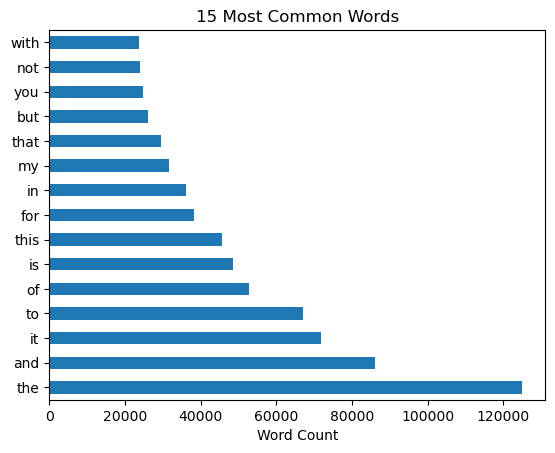

In [66]:
# Count each word across the training reviews
word_counts = pd.Series(
    train_bow.sum(axis=0).A1,
    index=bow.get_feature_names_out()
)

# Find the 15 most common words
top_words = word_counts.nlargest(15)

top_words.plot(kind="barh")
plt.title("15 Most Common Words")
plt.xlabel("Word Count")
plt.show()

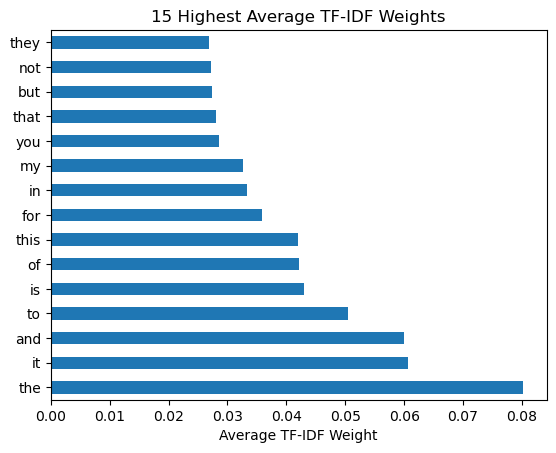

In [68]:
# Find each word's average TF-IDF weight
word_weights = pd.Series(
    train_tfidf.mean(axis=0).A1,
    index=tfidf.get_feature_names_out()
)

# Select the 15 highest averages
top_words = word_weights.nlargest(15)

# Make the chart
top_words.plot(kind="barh")
plt.title("15 Highest Average TF-IDF Weights")
plt.xlabel("Average TF-IDF Weight")
plt.show()